# Notebook 05: Automated Paper Artifacts & Publication Visualizations

This notebook orchestrates publication artifact generation for the MCTS-HNM manuscript:
1. Loads paper metadata from `paper_metadata.yaml` (title, authors, PPGC UFRGS affiliation).
2. Reads verified real benchmark results in REAL mode; synthetic fixtures are restricted to SMOKE mode.
3. Renders and exports publication-grade vector PDF and raster PNG figures into `paper/figures/`.
4. Renders and exports LaTeX `booktabs` tables into `paper/tables/`.
5. Compiles `paper/main.pdf` via pdflatex.


In [1]:
import os
import sys
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

# Ensure project root is in sys.path
root_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))

from src.utils.experiment_config import (
    ExecutionMode,
    ExperimentConfig,
    find_repo_root,
    get_isolated_paths,
    print_execution_banner,
)
from src.utils.paper_artifacts import (
    load_paper_metadata,
    generate_all_paper_artifacts,
    generate_pareto_cost_performance_plot,
    generate_coverage_entropy_dynamics_plot,
    generate_class_exposure_vs_delta_recall_plot,
    generate_ward_vs_semantic_dendrogram_plot,
    generate_interaction_ratio_plot,
    generate_precision_recall_curves_plot,
    generate_quadrant_evaluation_plot,
    compile_paper,
)

EXECUTION_MODE = ExecutionMode.REAL
if os.environ.get("EXECUTION_MODE"):
    EXECUTION_MODE = ExecutionMode(os.environ["EXECUTION_MODE"].lower())
elif "pytest" in sys.modules:
    EXECUTION_MODE = ExecutionMode.SMOKE

repo_root = find_repo_root()
config = ExperimentConfig(
    execution_mode=EXECUTION_MODE,
    seed=42,
    num_steps=100,
)
print_execution_banner(config, notebook_name="05_paper_artifacts")
paths = get_isolated_paths(config, repo_root=repo_root)


EXPERIMENT MODE: REAL
Dataset: CIFAR-100
Synthetic fallback: DISABLED
Scientific results: ENABLED
Notebook: 05_paper_artifacts
Mode: REAL
Output directory: /home/mlima/workspace/mcts-hnm/results/real


## 1. Paper Metadata Configuration
Inspecting metadata from `paper_metadata.yaml`:

In [2]:
meta = load_paper_metadata(repo_root / "paper_metadata.yaml")
print("Title:", meta.get("title"))
print("Authors:")
for a in meta.get("authors", []):
    print("  -", a.get("name"), f"({a.get('affiliation')})", f"<{a.get('email')}>")
print("Institution:")
print(meta.get("institution"))


Title: MCTS-HNM: Monte Carlo Tree Search for Hierarchical Hard Negative Mining in Class-Imbalanced Learning
Authors:
  - Matheus de Lima (PPGC - Universidade Federal do Rio Grande do Sul (UFRGS)) <placeholder@inf.ufrgs.br>
  - Co-Author Placeholder (PPGC - Universidade Federal do Rio Grande do Sul (UFRGS)) <coauthor@inf.ufrgs.br>
Institution:
Postgraduate Program in Computer Science (PPGC)
Universidade Federal do Rio Grande do Sul (UFRGS)
Porto Alegre, RS, Brazil


## 2. Generate Publication Figures and Tables

Generating publication artifacts with strict provenance and scientific data integrity:
- **Mandatory Artifacts**: Convergence curves (Fig 1), Scenario 1 table (Tab 1), Scenario 2 curriculum table (Tab 2), and Hierarchy ablation table (Tab 3). A missing mandatory metric halts generation with an error.
- **Optional Artifacts**: Tree visitation heatmap (Fig 2) and Hyperparameter sensitivity plot (Fig 3). If real measurements are absent, they are skipped and recorded as `SKIPPED` in the manifest without fabricating synthetic data. If present but malformed, validation fails fast.

Generating all figures (PDF & PNG) and tables (LaTeX booktabs):

In [3]:
artifacts = generate_all_paper_artifacts(
    results_dir=paths.results_dir,
    paper_dir=repo_root / "paper" if EXECUTION_MODE == ExecutionMode.REAL else paths.paper_figures_dir.parent,
    metadata_path=repo_root / "paper_metadata.yaml",
    config=config,
    optional_artifacts=("visitation_heatmap", "sensitivity_plot"),
)

print(f"Artifact generation status: {artifacts.get('status')}")
if artifacts.get("skipped"):
    print("\nSkipped optional artifacts:")
    for art, reason in artifacts["skipped"].items():
        print(f"  - [{art}]: {reason}")

print("\nGenerated figures:")
for fig in artifacts["figures"]:
    print(f"  - {fig}")

print("\nGenerated tables:")
for tab in artifacts["tables"]:
    print(f"  - {tab}")

print(f"\nArtifact Manifest: {artifacts.get('manifest')}")


Omitted optional figure coverage_entropy: Per-step class coverage has not been retained; the two-panel figure remains unavailable
Omitted optional figure exposure_recall: Atomic run lacks per-class exposure/recall; older runs cannot be treated as paired measurements
Omitted optional figure interaction_ratio: FIG-05 requires >=2 measured imbalance ratios per strategy; currently only one is available. Run 1:10 and/or 1:100 before plotting.
Omitted optional figure precision_recall: Per-seed y_true/y_score or measured PR points are not exported; cannot infer a PR curve from AUPRC
Omitted optional figure evaluation_quadrants: Four actual test quadrants per strategy/seed not available in historical atomic runs


Artifact generation status: partial

Skipped optional artifacts:
  - [coverage_entropy]: Per-step class coverage has not been retained; the two-panel figure remains unavailable
  - [exposure_recall]: Atomic run lacks per-class exposure/recall; older runs cannot be treated as paired measurements
  - [interaction_ratio]: FIG-05 requires >=2 measured imbalance ratios per strategy; currently only one is available. Run 1:10 and/or 1:100 before plotting.
  - [precision_recall]: Per-seed y_true/y_score or measured PR points are not exported; cannot infer a PR curve from AUPRC
  - [evaluation_quadrants]: Four actual test quadrants per strategy/seed not available in historical atomic runs

Generated figures:
  - /home/mlima/workspace/mcts-hnm/paper/figures/fig_convergence_curves.pdf
  - /home/mlima/workspace/mcts-hnm/paper/figures/fig_convergence_curves.png
  - /home/mlima/workspace/mcts-hnm/paper/figures/fig_tree_visitation_heatmap.pdf
  - /home/mlima/workspace/mcts-hnm/paper/figures/fig_tree_

## 3. Interactive Visualization of Publication Figures

### Figure 1: Convergence Curves

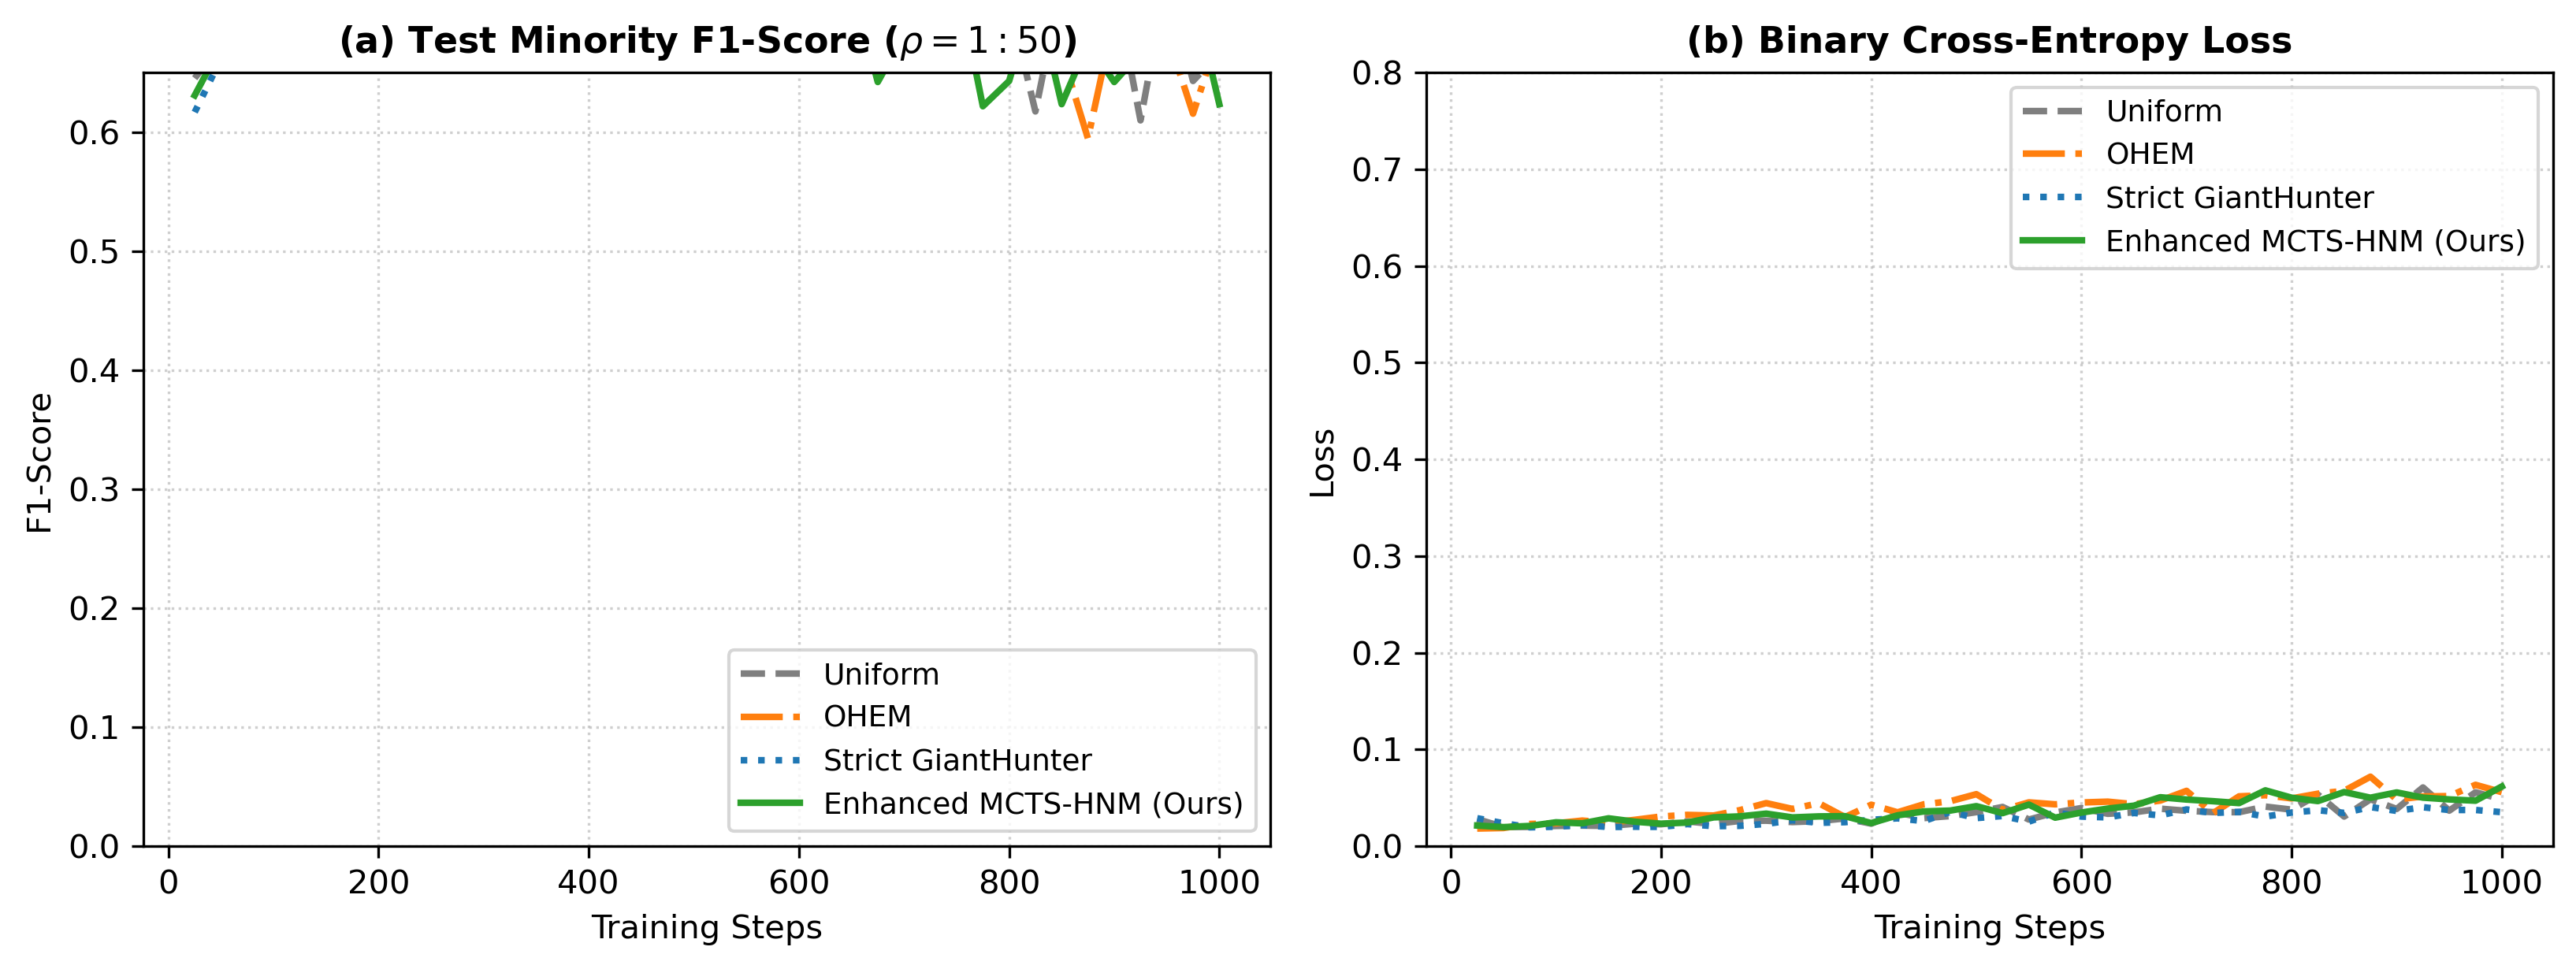

### Figure 2: Tree Visitation Heatmap

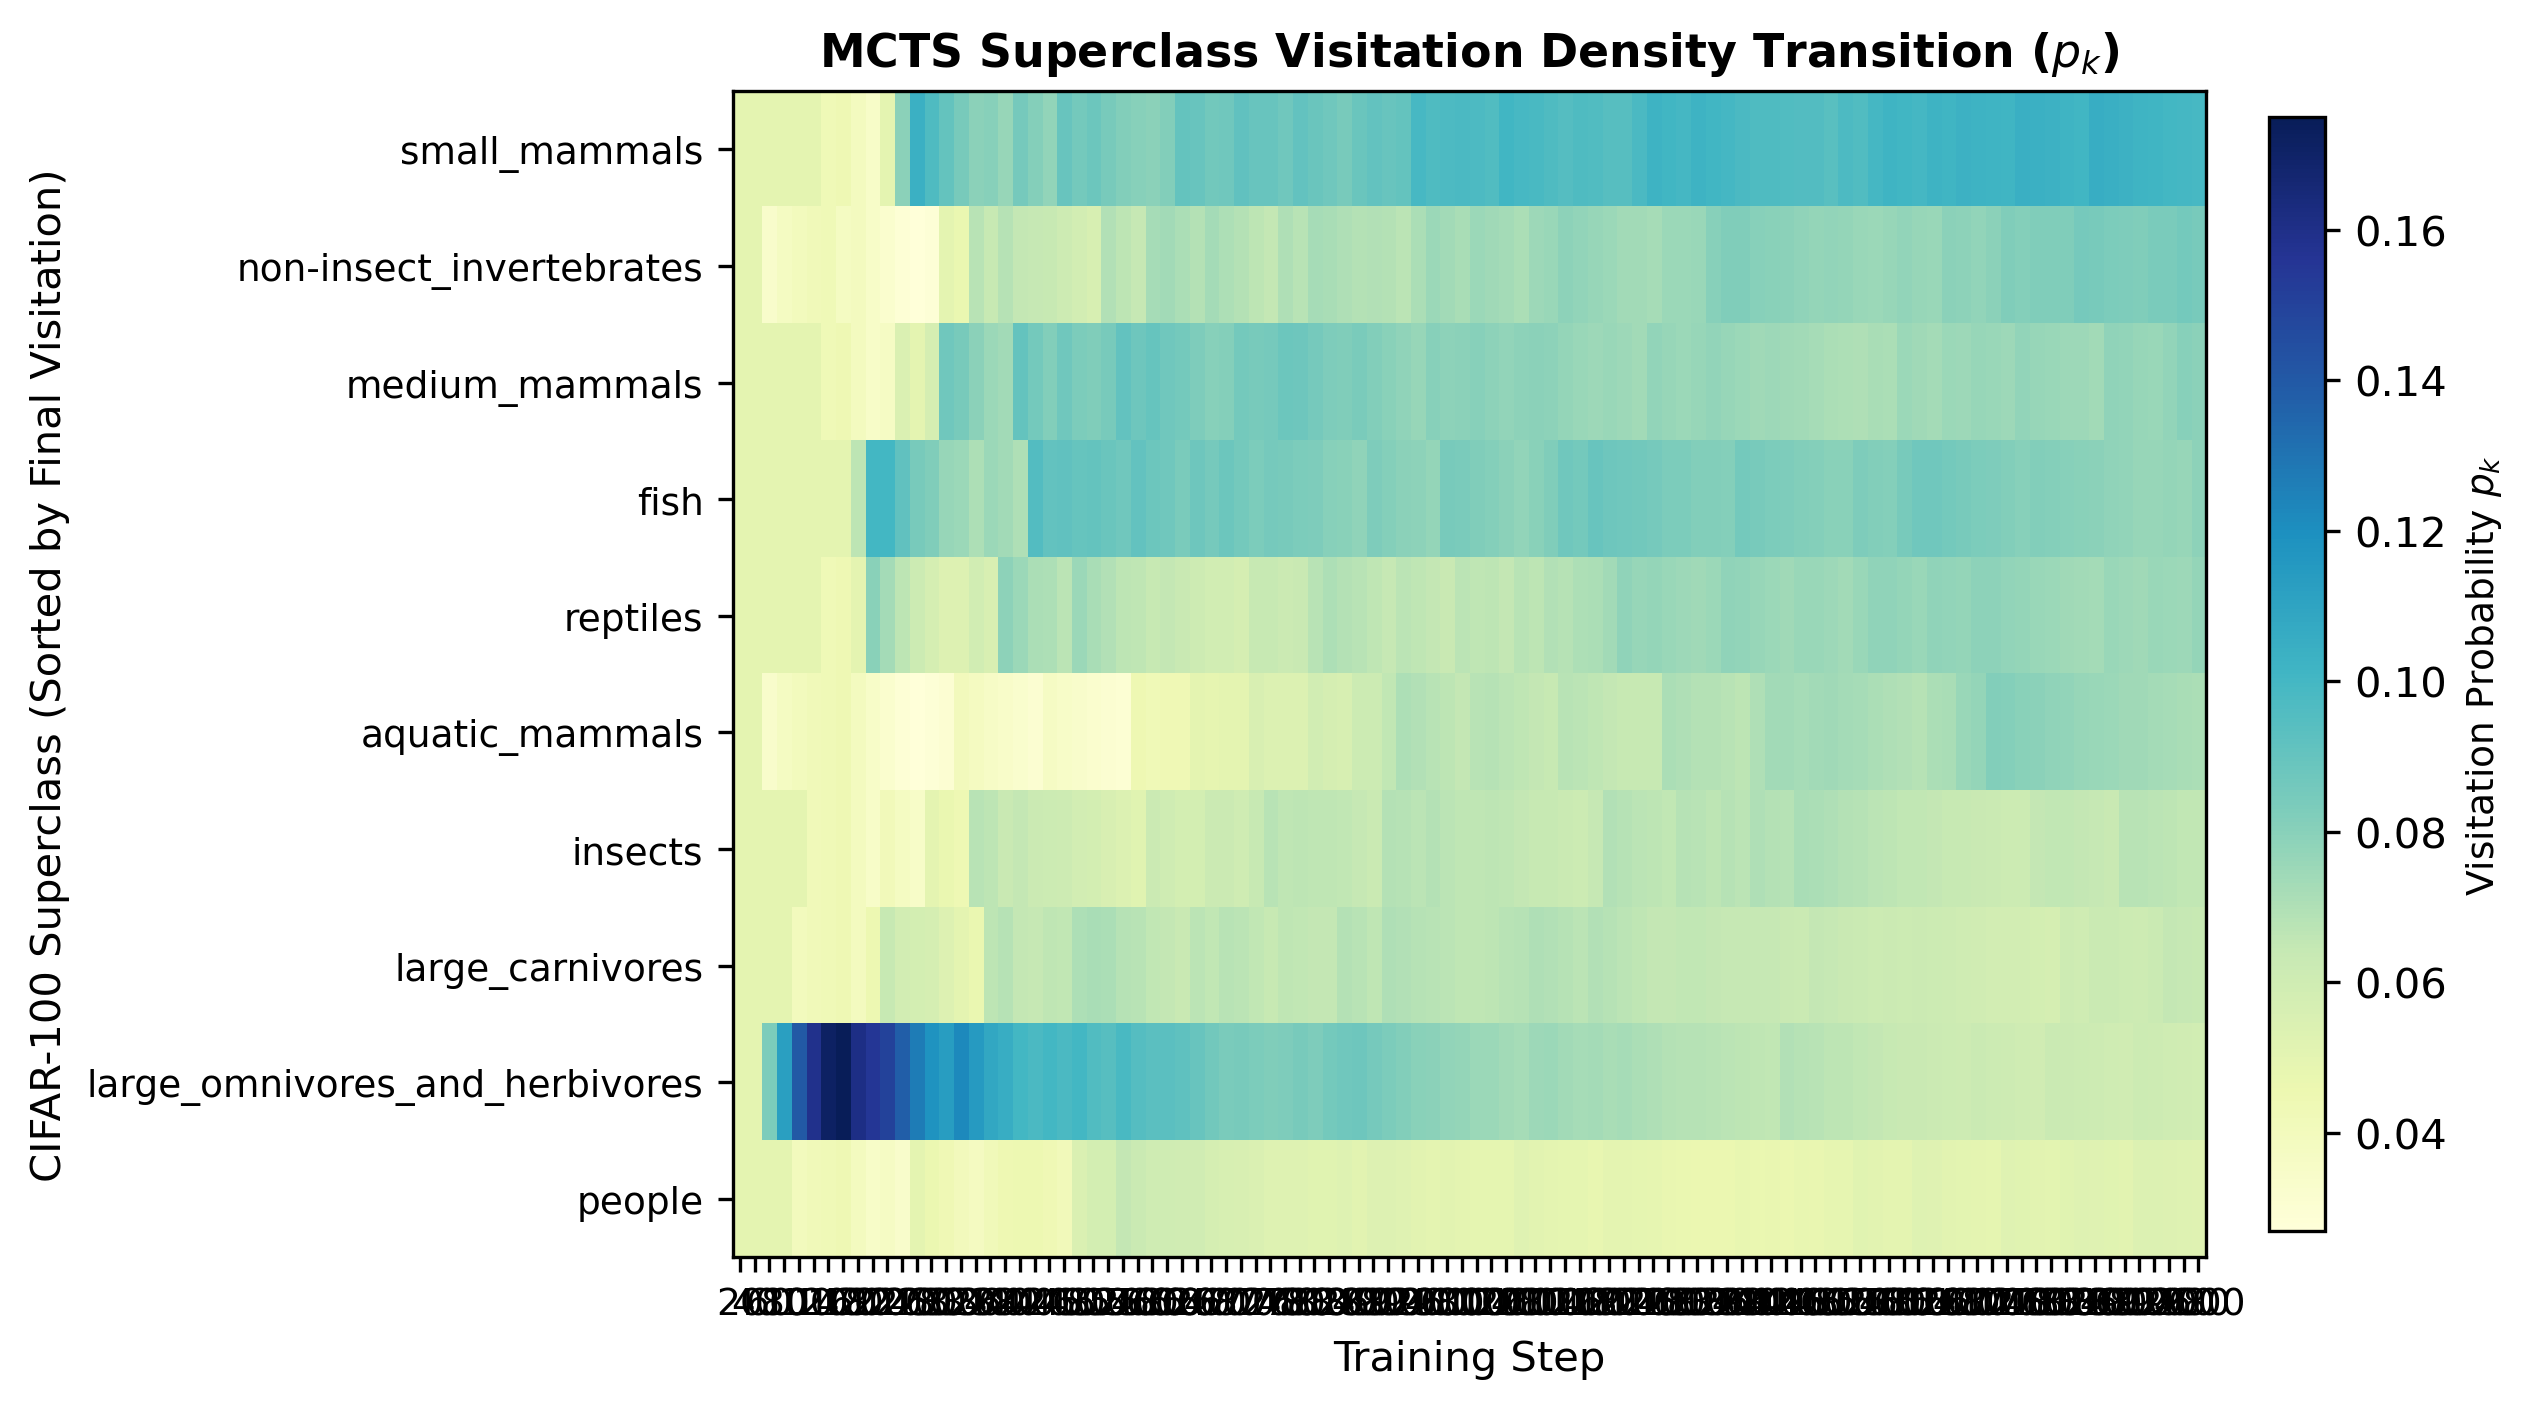

### Supplementary: Measured Scenario-2 Visitation Entropy

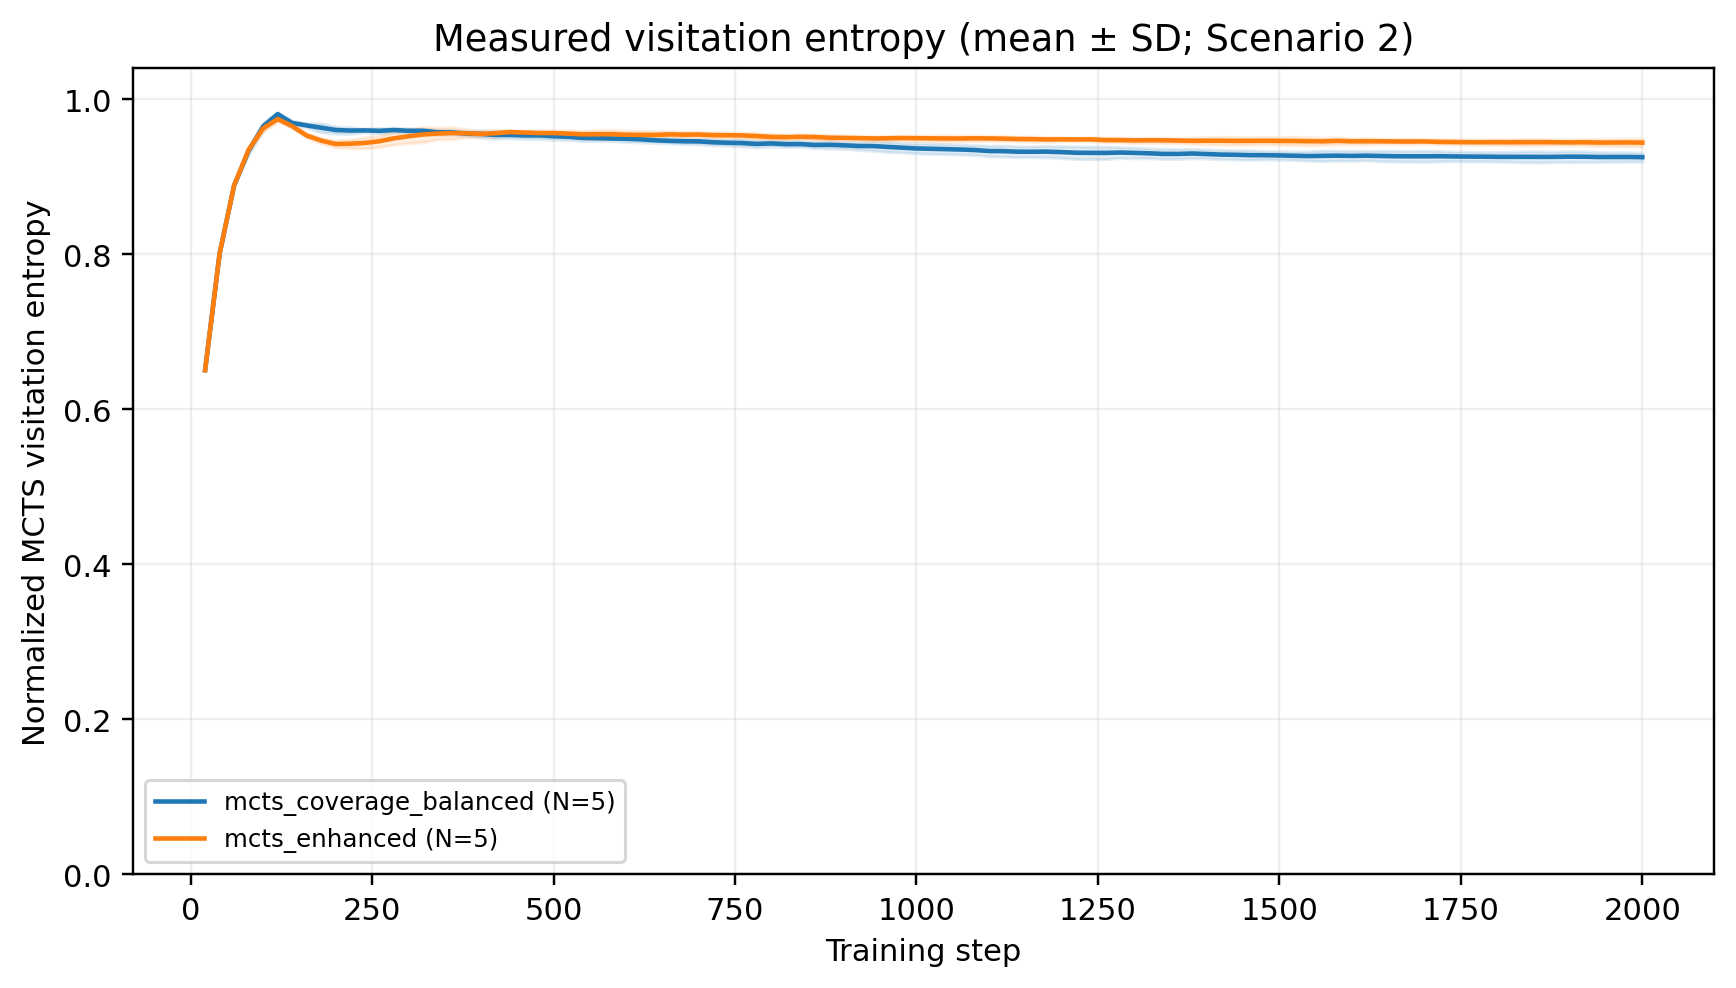

### Figure 3: Hyperparameter Sensitivity

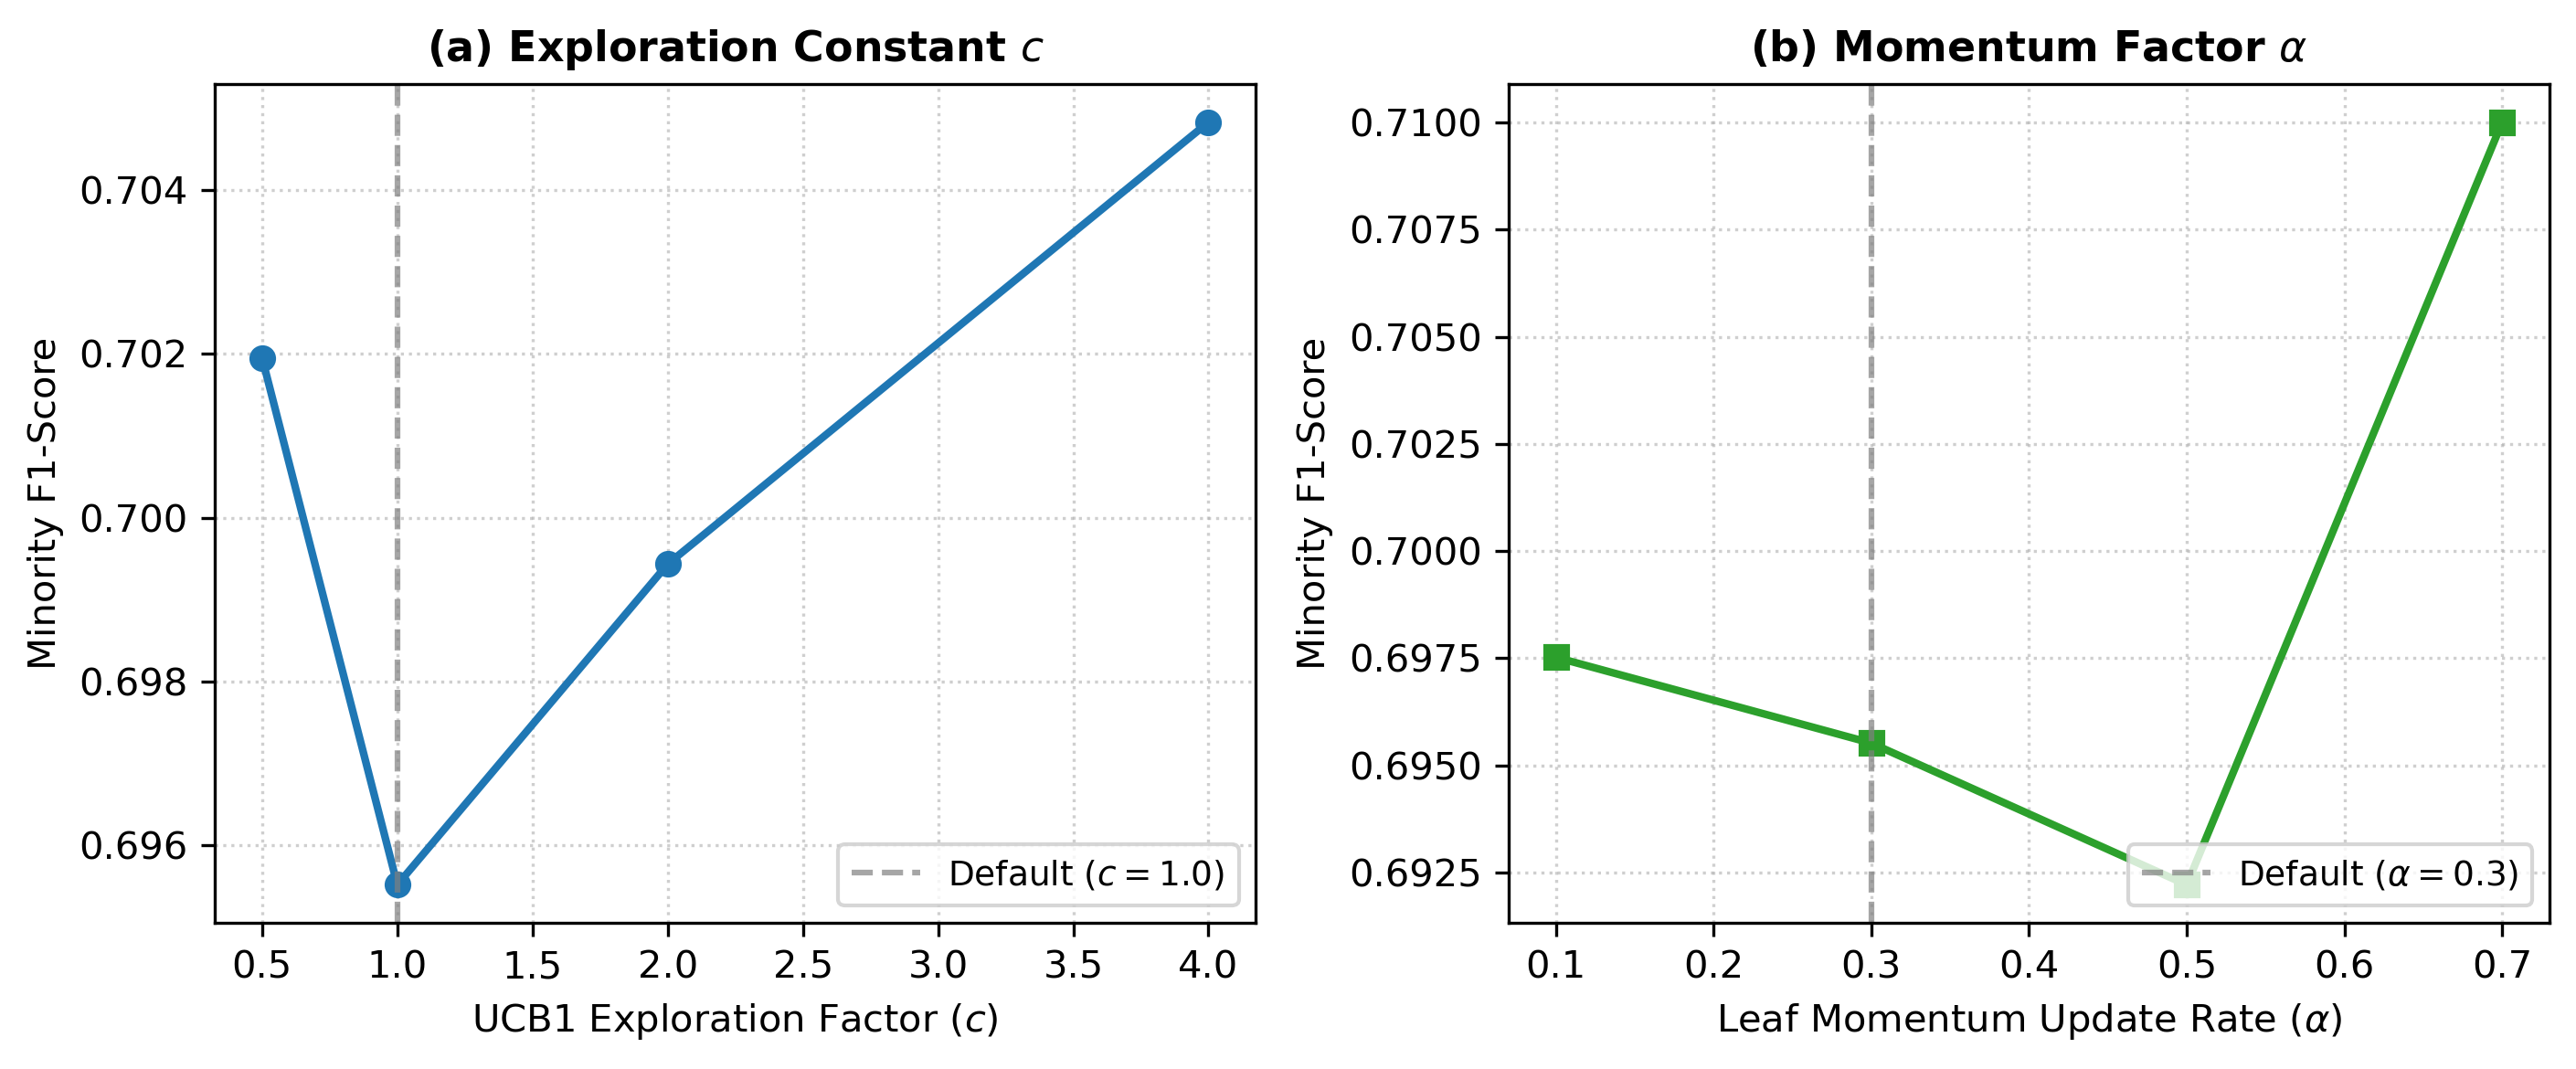

### Figure 4: 2x2 Factorial Mechanism Ablation (QNorm x Dual-Stream)

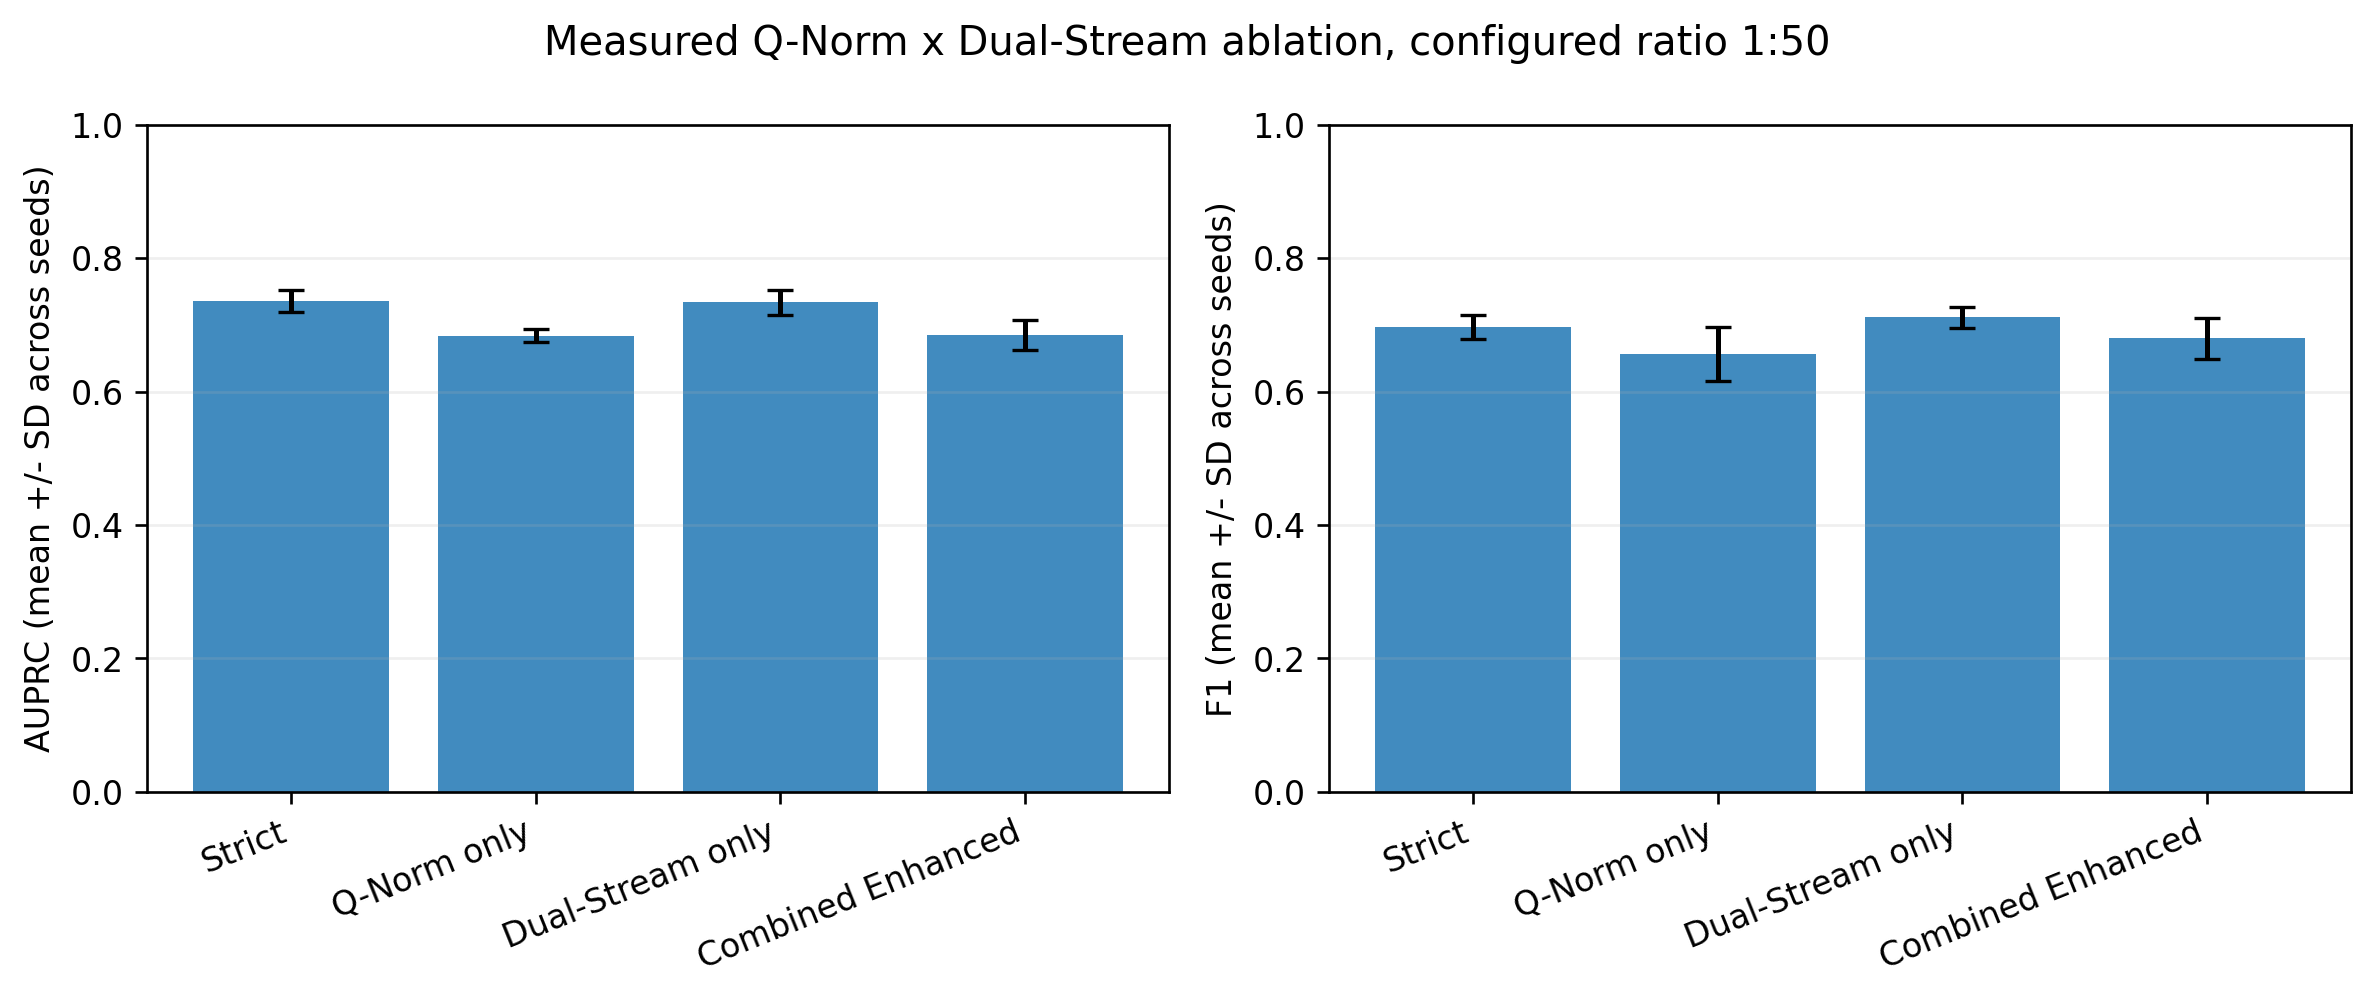

### Figure 5: Pareto Frontier: Cost vs. Performance (FIG-01)

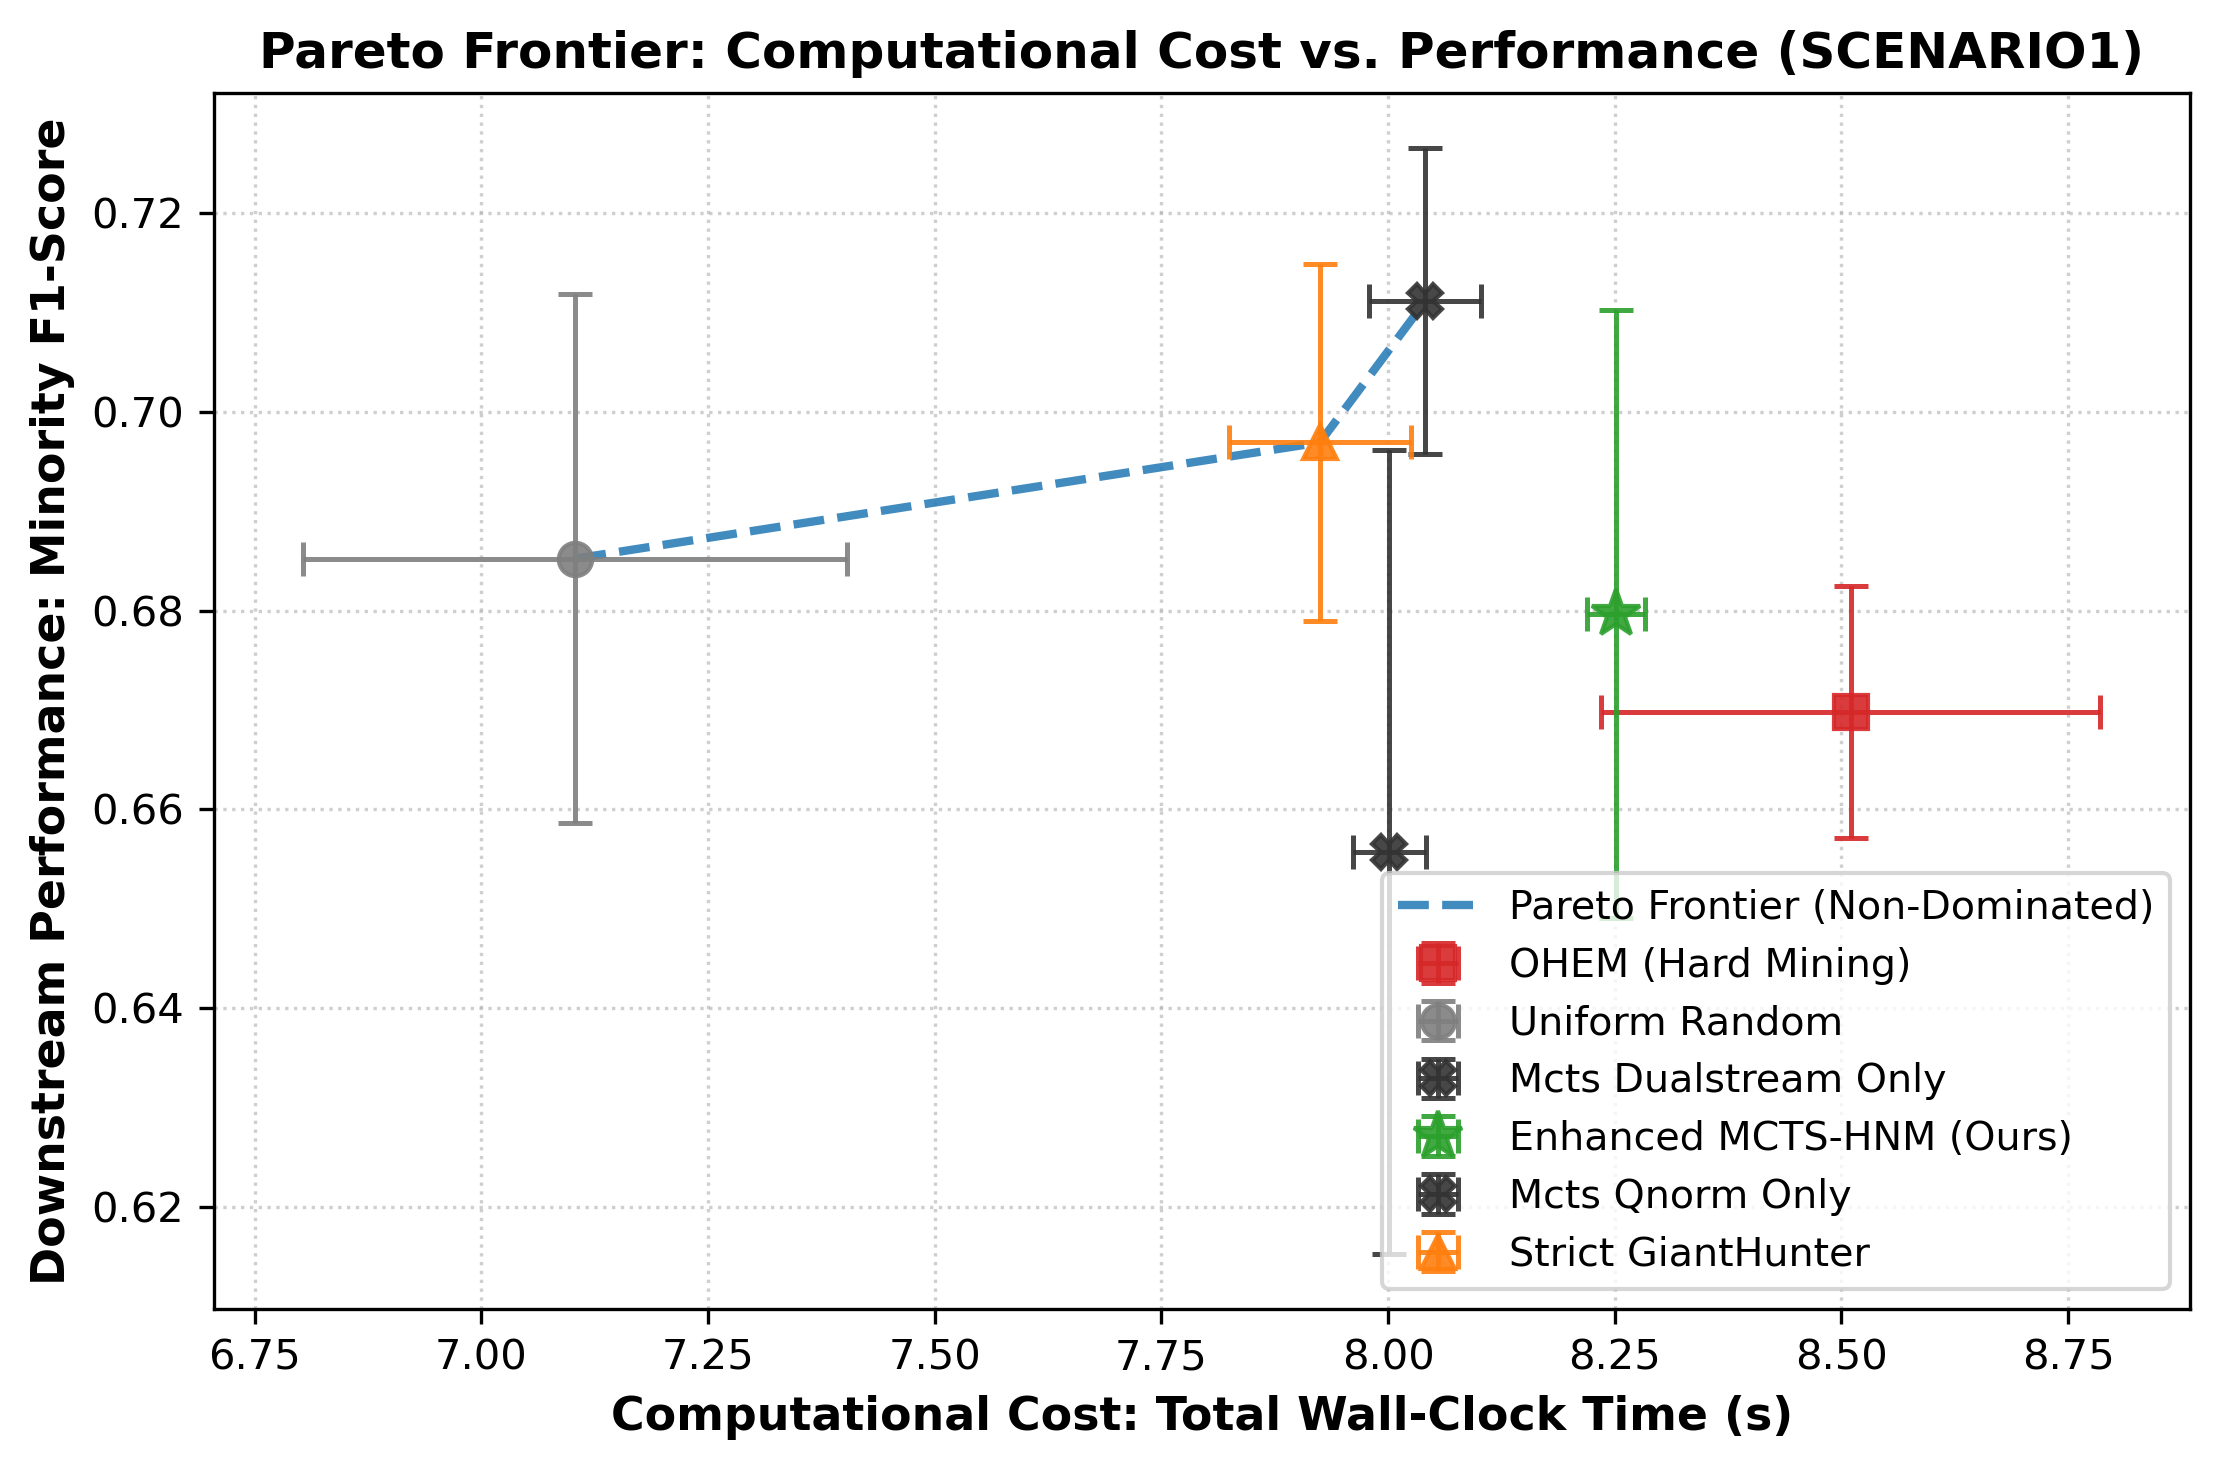

### Figure 6: Normalized Visitation Entropy & Class Coverage Dynamics (FIG-02)

_Coverage and entropy dynamics figure not found on disk._

### Figure 7: Class Exposure vs. Marginal Recall Gain (FIG-03)

_Class exposure vs delta recall figure not found on disk._

### Figure 8: Ward Confusion Dendrogram vs. Semantic Hierarchy (FIG-04)

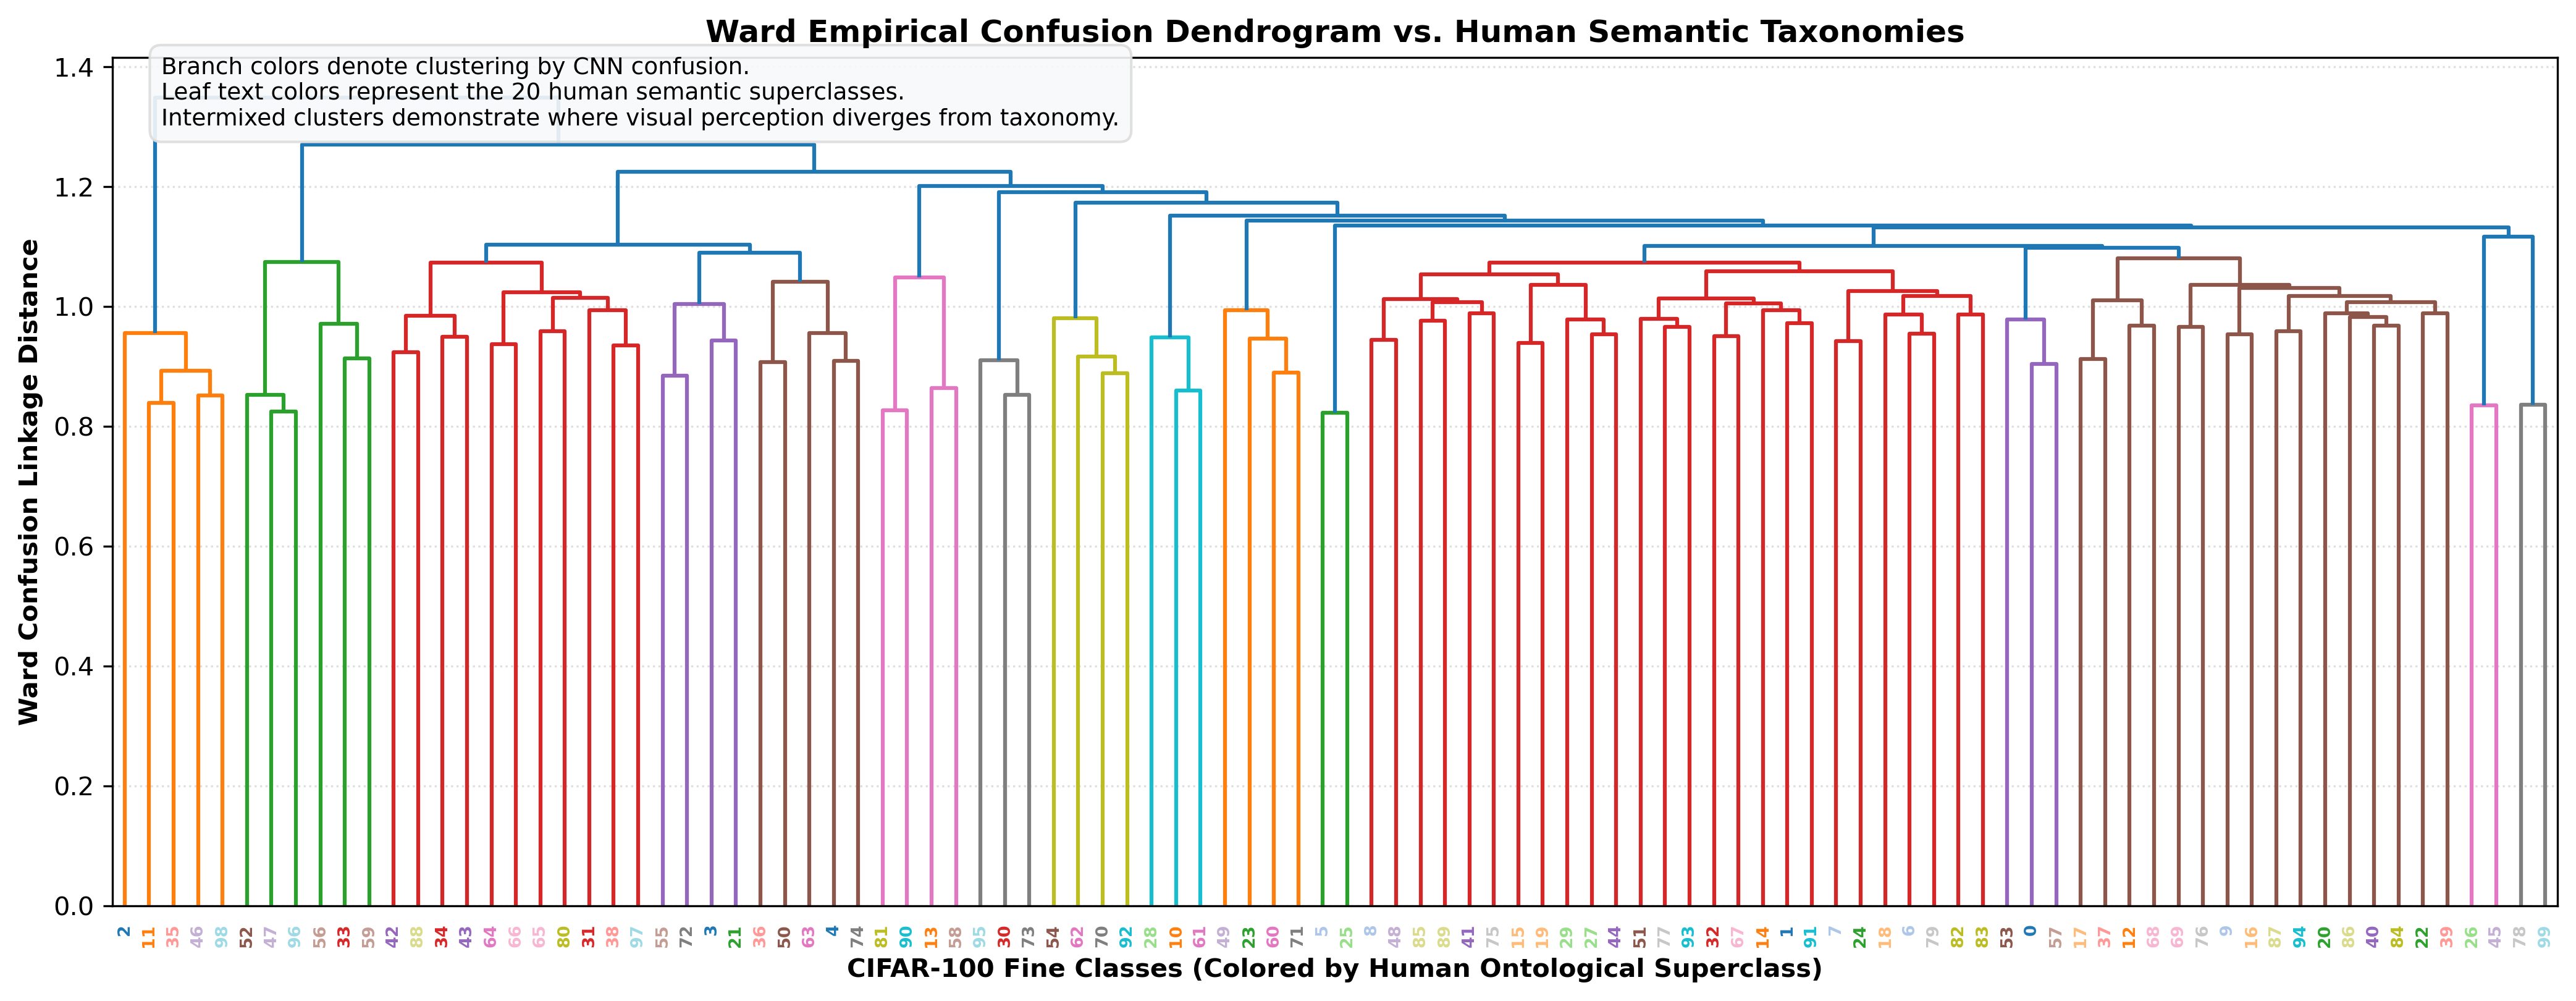

### Figure 9: Method by Imbalance Ratio Interaction (FIG-05)

_Interaction ratio figure not found on disk._

### Figure 10: Aggregated Precision-Recall Curves (FIG-06)

_Precision-Recall curves figure not found on disk._

### Figure 11: 4-Quadrant Evaluation Trade-off (FIG-07)

_4-Quadrant evaluation figure not found on disk._

... (3 outputs left out)

**Table: `tab_scenario1_imbalanced.tex`**

```latex
% Auto-generated by src/utils/paper_artifacts.py
\begin{table*}[t]
\centering
\small
\caption{Scenario 1: Imbalanced Binary One-vs-Rest evaluation on CIFAR-100 across 5 random seeds ($N=5$) at imbalance ratio $\rho = 1:50$. Reporting mean $\pm$ standard deviation for F1-Score, AUPRC, and False Positive Rate at 95\% recall (FPR@95). $p$-values computed via paired Student's $t$-test against Enhanced MCTS-HNM.}
\label{tab:scenario1_imbalanced}
\begin{tabular}{llcccc}
\toprule
Imbalance ($\rho$) & Negative Mining Strategy & Minority F1-Score (\%) & AUPRC & FPR@95 ($\downarrow$) & $p$-value ($t$-test) \\
\midrule
  1:50 & Uniform Random & 68.5 $\pm$ 2.7 & 0.708 $\pm$ 0.038 & 0.282 $\pm$ 0.134 & $p = 0.646$ \\
  1:50 & OHEM (Shrivastava et al.) & 67.0 $\pm$ 1.3 & 0.703 $\pm$ 0.013 & 0.326 $\pm$ 0.177 & $p = 0.463$ \\
  1:50 & Strict GiantHunter (Qu et al.) & 69.7 $\pm$ 1.8 & 0.736 $\pm$ 0.017 & 0.240 $\pm$ 0.117 & $p = 0.389$ \\
  1:50 & \textbf{Enhanced MCTS-HNM (Ours)} & 68.0 $\pm$ 3.1 & 0.685 $\pm$ 0.023 & 0.356 $\pm$ 0.169 & --- (Reference) \\
\bottomrule
\end{tabular}
\end{table*}

```

**Table: `tab_scenario2_multiclass.tex`**

```latex
% Auto-generated by src/utils/paper_artifacts.py
\begin{table}[t]
\centering
\small
\caption{Scenario 2: 100-way multi-class curriculum classification on CIFAR-100 across 5 random seeds ($N=5$). Evaluating Top-1 Accuracy, Macro-Averaged F1-Score, and Worst-10-Class Recall.}
\label{tab:scenario2_multiclass}
\begin{tabular}{lcccc}
\toprule
Strategy & Top-1 Accuracy (\%) & Macro-F1 (\%) & Worst-10 Recall (\%) & $p$-value ($t$-test) \\
\midrule
  Uniform Random & 63.9 $\pm$ 0.4 & 63.7 $\pm$ 0.4 & 33.5 $\pm$ 1.5 & $p < 0.001$ \\
  \textbf{Enhanced MCTS-HNM (Ours)} & 33.4 $\pm$ 1.5 & 34.3 $\pm$ 1.4 & 0.7 $\pm$ 0.5 & --- (Ref) \\
\bottomrule
\end{tabular}
\end{table}

```

In [4]:
fig_dir = paths.paper_figures_dir if EXECUTION_MODE == ExecutionMode.SMOKE else repo_root / "paper" / "figures"
tab_dir = paths.paper_tables_dir if EXECUTION_MODE == ExecutionMode.SMOKE else repo_root / "paper" / "tables"

display(Markdown("### Figure 1: Convergence Curves"))
conv_png = fig_dir / "fig_convergence_curves.png"
if conv_png.exists():
    display(Image(filename=str(conv_png)))
else:
    display(Markdown("_Convergence curves figure not found on disk._"))

display(Markdown("### Figure 2: Tree Visitation Heatmap"))
heat_png = fig_dir / "fig_tree_visitation_heatmap.png"
if heat_png.exists():
    display(Image(filename=str(heat_png)))
else:
    skip_msg = artifacts.get("skipped", {}).get("visitation_heatmap", "Optional figure omitted (no visitation data).")
    display(Markdown(f"> **Notice (Optional Figure Omitted):** {skip_msg}"))

display(Markdown("### Supplementary: Measured Scenario-2 Visitation Entropy"))
phase1_entropy_png = fig_dir / "fig_measured_visitation_entropy.png"
if phase1_entropy_png.exists():
    display(Image(filename=str(phase1_entropy_png)))
else:
    why = artifacts.get("skipped", {}).get("measured_visitation_entropy", "Not available")
    display(Markdown(f"_Measured entropy plot omitted: {why}_"))

display(Markdown("### Figure 3: Hyperparameter Sensitivity"))
sens_png = fig_dir / "fig_hyperparameter_sensitivity.png"
if sens_png.exists():
    display(Image(filename=str(sens_png)))
else:
    skip_msg = artifacts.get("skipped", {}).get("sensitivity_plot", "Optional figure omitted (no sensitivity data).")
    display(Markdown(f"> **Notice (Optional Figure Omitted):** {skip_msg}"))

display(Markdown("### Figure 4: 2x2 Factorial Mechanism Ablation (QNorm x Dual-Stream)"))
abl_png = fig_dir / "fig_ablation_2x2.png"
if abl_png.exists():
    display(Image(filename=str(abl_png)))
else:
    display(Markdown("_2x2 Factorial ablation figure omitted (no ablation run data)._"))

display(Markdown("### Figure 5: Pareto Frontier: Cost vs. Performance (FIG-01)"))
pareto_png = fig_dir / "fig_pareto_cost_vs_accuracy.png"
if pareto_png.exists():
    display(Image(filename=str(pareto_png)))
else:
    display(Markdown("_Pareto frontier figure not found on disk._"))

display(Markdown("### Figure 6: Normalized Visitation Entropy & Class Coverage Dynamics (FIG-02)"))
entropy_png = fig_dir / "fig_coverage_entropy_dynamics.png"
if entropy_png.exists():
    display(Image(filename=str(entropy_png)))
else:
    display(Markdown("_Coverage and entropy dynamics figure not found on disk._"))

display(Markdown("### Figure 7: Class Exposure vs. Marginal Recall Gain (FIG-03)"))
exp_png = fig_dir / "fig_class_exposure_vs_delta_recall.png"
if exp_png.exists():
    display(Image(filename=str(exp_png)))
else:
    display(Markdown("_Class exposure vs delta recall figure not found on disk._"))

display(Markdown("### Figure 8: Ward Confusion Dendrogram vs. Semantic Hierarchy (FIG-04)"))
dend_png = fig_dir / "fig_ward_vs_semantic_dendrogram.png"
if dend_png.exists():
    display(Image(filename=str(dend_png)))
else:
    display(Markdown("_Ward dendrogram figure not found on disk._"))

display(Markdown("### Figure 9: Method by Imbalance Ratio Interaction (FIG-05)"))
int_png = fig_dir / "fig_interaction_ratio_methods.png"
if int_png.exists():
    display(Image(filename=str(int_png)))
else:
    display(Markdown("_Interaction ratio figure not found on disk._"))

display(Markdown("### Figure 10: Aggregated Precision-Recall Curves (FIG-06)"))
pr_png = fig_dir / "fig_precision_recall_curves.png"
if pr_png.exists():
    display(Image(filename=str(pr_png)))
else:
    display(Markdown("_Precision-Recall curves figure not found on disk._"))

display(Markdown("### Figure 11: 4-Quadrant Evaluation Trade-off (FIG-07)"))
quad_png = fig_dir / "fig_evaluation_4quadrants_comparison.png"
if quad_png.exists():
    display(Image(filename=str(quad_png)))
else:
    display(Markdown("_4-Quadrant evaluation figure not found on disk._"))

display(Markdown("### Generated LaTeX Tables"))
for tab_file in sorted(tab_dir.glob("*.tex")):
    display(Markdown(f"**Table: `{tab_file.name}`**"))
    with open(tab_file, "r") as tf:
        display(Markdown(f"```latex\n{tf.read()}\n```"))


## 4. Compile LaTeX Manuscript
Compiling `paper/main.tex` to `paper/main.pdf`:

In [5]:
try:
    target_paper_dir = repo_root / "paper"
    pdf_path = compile_paper(target_paper_dir)
    print(f"Successfully compiled: {pdf_path} ({pdf_path.stat().st_size:,} bytes)")
except Exception as e:
    print(f"Compilation notice: {e}")


Compilation notice: LaTeX compiler 'pdflatex' not found on PATH.
